# NearestCart: E-Commerce Product Recommendation Prototype
### Feature-Space K-Nearest Neighbors (KNN) System
**Project 30** | Applied Machine Learning Practice
***

## 1. Business Context & Objective
In modern retail e-commerce platforms, providing relevant real-time product recommendations is essential for user engagement and conversion. While collaborative filtering relies on past user browsing and transaction history, **content-based feature-space recommendation** allows systems to immediately recommend relevant products based strictly on standardized continuous product specifications and attributes.

### Key Project Deliverables:
1. **Module 1: Top-K Nearest-Neighbor Retrieval Engine** outputting bounded product similarity scores.
2. **Module 2: Distance-Weighted Neighbor Ranking Script** applying reciprocal distance weighting ( = rac{1}{d_i + \epsilon}$).
3. **Module 3: Latency & Scalability Benchmark** evaluating query latency as the catalog scales from ,000$ to ,000$ products across **Brute-Force**, **KD-Tree**, and **Ball-Tree** spatial indexing structures.
4. **Supervised KNN Extension**: Evaluating category classification using feature vectors.


## 2. Dataset Schema: catalog_product_attributes
The recommendation prototype is developed around the assigned seven-column retail schema:

| Column Name | Data Type | Role in Engine | Description |
| :--- | :--- | :--- | :--- |
| **sku_id** | Categorical / String | Identifier | Unique product identifier (e.g. SKU_00005). Excluded from distance metrics. |
| **unit_price** | Numerical (Continuous) | Predictor Feature | Retail selling price in INR (Rs.). |
| **verage_user_rating** | Numerical (Continuous) | Predictor Feature | Average customer review rating (.00$ to .00$ scale). |
| **
eview_volume** | Numerical (Continuous) | Predictor Feature | Total number of customer reviews logged. |
| **product_weight_grams**| Numerical (Continuous) | Predictor Feature | Net physical weight in grams ($). |
| **package_volume_cm3** | Numerical (Continuous) | Predictor Feature | Packaged volume in cubic centimeters ($	ext{cm}^3 = L 	imes W 	imes H$). |
| **product_category** | Categorical | Filter / Target | High-level retail category (Electronics, Apparel, Footwear, etc.). |


## Step 1: Environment Setup & Data Loading
We import standard data science and machine learning libraries: pandas, 
umpy, matplotlib, seaborn, and scikit-learn.
We also configure OMP_NUM_THREADS = 1 to ensure thread safety and optimal memory performance.


In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Configure plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

# Load the catalog dataset
data_path = os.path.join("data", "catalog_product_attributes.csv")
df = pd.read_csv(data_path)

print(f"Catalog Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Catalog Dataset Shape: 5000 rows, 7 columns


,sku_id,unit_price,average_user_rating,review_volume,product_weight_grams,package_volume_cm3,product_category
0,SKU_00001,3001.94,3.75,364,3018.2,12449.0,Home & Kitchen
1,SKU_00002,622.27,4.76,356,214.5,591.6,Books & Stationery
2,SKU_00003,1987.78,3.16,193,1058.9,4048.3,Sports & Fitness
3,SKU_00004,1807.10,3.41,923,758.1,4373.4,Footwear
4,SKU_00005,13728.60,4.29,379,293.4,2245.9,Electronics


## Step 2: Exploratory Data Analysis (EDA) & Data Integrity Checks
Before performing feature space computations, we inspect the catalog for:
- Missing values ($)
- Duplicate rows
- Category distribution balance
- Descriptive statistics across continuous features


In [2]:
# Check missing values and duplicates
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated(subset=["sku_id"]).sum()

print(f"Total Missing Values: {missing_count}")
print(f"Duplicate SKU IDs:    {duplicate_count}")

# Summary statistics
print("\nDescriptive Statistics for Continuous Features:")
display(df.describe().T)


Total Missing Values: 0
Duplicate SKU IDs:    0

Descriptive Statistics for Continuous Features:


,count,mean,std,min,25%,50%,75%,max
unit_price,5000.0,6694.146664,12481.179400,203.35,1279.0875,2466.42,5964.4975,93658.81
average_user_rating,5000.0,4.214718,0.464762,1.99,3.9300,4.28,4.5800,4.99
review_volume,5000.0,423.692800,889.956194,5.00,73.7500,175.00,428.0000,25558.00
product_weight_grams,5000.0,3241.775500,5984.529255,35.00,264.3750,701.15,2122.5000,31778.30
package_volume_cm3,5000.0,12912.807040,28687.710905,251.50,932.4750,3278.70,6443.8000,189798.30


C:\Users\RAHUL\AppData\Local\Temp\ipykernel_27132\2925573372.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y="product_category", order=order, ax=axes[0], palette="Blues_r")


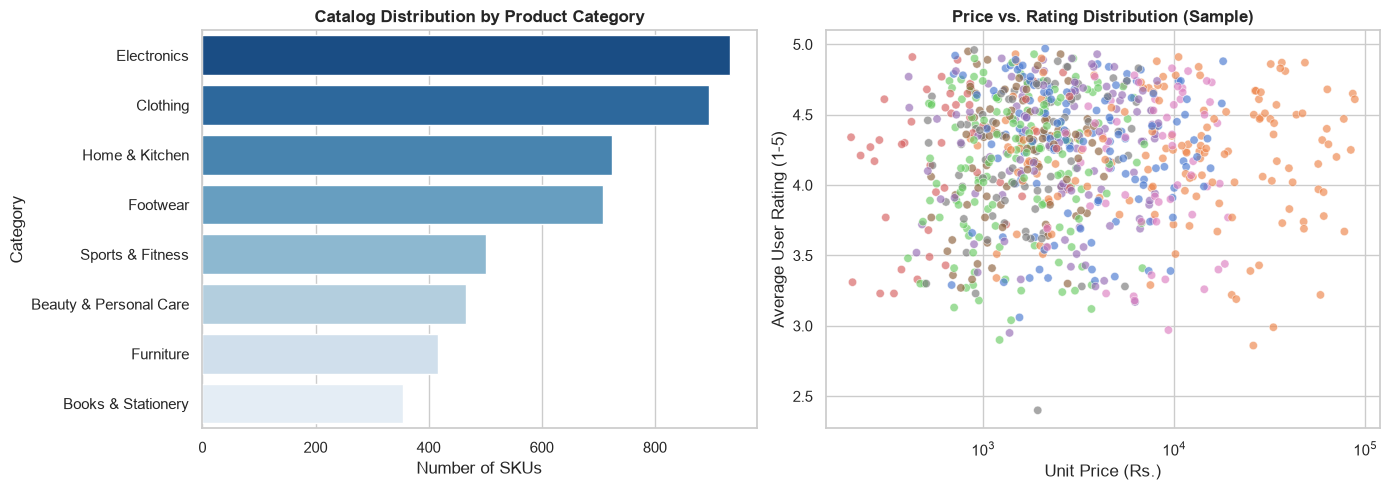

In [3]:
# Visualize Category Distribution and Feature Densities
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Product Category Distribution
order = df["product_category"].value_counts().index
sns.countplot(data=df, y="product_category", order=order, ax=axes[0], palette="Blues_r")
axes[0].set_title("Catalog Distribution by Product Category", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of SKUs")
axes[0].set_ylabel("Category")

# 2. Rating vs Price scatter colored by category
sample_df = df.sample(n=800, random_state=42)
sns.scatterplot(
    data=sample_df,
    x="unit_price",
    y="average_user_rating",
    hue="product_category",
    alpha=0.65,
    ax=axes[1],
    legend=False
)
axes[1].set_title("Price vs. Rating Distribution (Sample)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Unit Price (Rs.)")
axes[1].set_ylabel("Average User Rating (1-5)")
axes[1].set_xscale("log")

plt.tight_layout()
plt.show()


## Step 3: Feature Space Standardization (StandardScaler)
### The Importance of Scaling in Distance-Based Models
In K-Nearest Neighbors, similarity is measured via geometric distance (e.g. Euclidean distance):
d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{j=1}^{D} (x_j - y_j)^2}

Because features like unit_price (Rs. $ to ,000$) and package_volume_cm3 ($ to ,000\text{ cm}^3$) have numerical magnitudes orders of magnitude larger than verage_user_rating (.0$ to .0$), unscaled distance calculations would be completely dominated by price and volume, rendering user ratings and weights mathematically irrelevant.

We apply **StandardScaler** to transform all features to zero mean and unit variance:
z = \frac{x - \mu}{\sigma}


In [4]:
FEATURE_COLS = [
    "unit_price",
    "average_user_rating",
    "review_volume",
    "product_weight_grams",
    "package_volume_cm3"
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[FEATURE_COLS])
scaled_feature_df = pd.DataFrame(X_scaled, columns=[f"{col}_scaled" for col in FEATURE_COLS])

print("Standardized Feature Matrix (Mean ? 0, Std ? 1):")
print(scaled_feature_df.describe().loc[["mean", "std"]].round(4))


Standardized Feature Matrix (Mean ? 0, Std ? 1):
      unit_price_scaled  average_user_rating_scaled  review_volume_scaled  \
mean             0.0000                     -0.0000                0.0000   
std              1.0001                      1.0001                1.0001   

      product_weight_grams_scaled  package_volume_cm3_scaled  
mean                      -0.0000                     0.0000  
std                        1.0001                     1.0001  


## Step 4: Module 1: Top-K Nearest-Neighbor Retrieval Engine
We construct an unsupervised NearestNeighbors retrieval engine using spatial indexing (lgorithm='kd_tree', metric='euclidean').

### Bounded Similarity Score:
Raw Euclidean distance  \in [0, \infty)$ is monotonically decreasing with similarity. To produce an intuitive, bounded percentage score $[0, 100\%]$, we use the reciprocal transformation:
\text{Similarity Score (\%)} = \frac{1}{1 + d} \times 100
- When  = 0$ (identical product), $\text{Similarity} = 100\%$.
- As  \to \infty$, $\text{Similarity} \to 0\%$.


In [5]:
# Fit NearestNeighbors Index
knn_engine = NearestNeighbors(n_neighbors=250, algorithm="kd_tree", metric="euclidean")
knn_engine.fit(X_scaled)

sku_to_idx = {sku: idx for idx, sku in enumerate(df["sku_id"])}

def retrieve_top_n_recommendations(target_sku_id, top_n=5, filter_category=True):
    """
    Module 1: Top-N Nearest Neighbor Retrieval Engine
    """
    if target_sku_id not in sku_to_idx:
        raise ValueError(f"SKU '{target_sku_id}' not found in catalog.")
        
    target_idx = sku_to_idx[target_sku_id]
    target_row = df.iloc[target_idx]
    target_vec = X_scaled[target_idx].reshape(1, -1)
    
    # Retrieve nearest neighbor candidates
    n_candidates = min(len(df), max(top_n * 50, 250) if filter_category else top_n + 1)
    distances, indices = knn_engine.kneighbors(target_vec, n_neighbors=n_candidates)
    
    results = []
    for dist, idx in zip(distances.flatten(), indices.flatten()):
        if idx == target_idx:
            continue  # Exclude target query product itself
            
        cand_row = df.iloc[idx]
        if filter_category and cand_row["product_category"] != target_row["product_category"]:
            continue  # Constrain search to matching category
            
        sim_pct = (1.0 / (1.0 + dist)) * 100.0
        results.append({
            "rank": len(results) + 1,
            "sku_id": cand_row["sku_id"],
            "product_category": cand_row["product_category"],
            "unit_price": cand_row["unit_price"],
            "average_user_rating": cand_row["average_user_rating"],
            "review_volume": int(cand_row["review_volume"]),
            "product_weight_grams": cand_row["product_weight_grams"],
            "package_volume_cm3": cand_row["package_volume_cm3"],
            "euclidean_distance": round(float(dist), 4),
            "similarity_score_pct": round(float(sim_pct), 2)
        })
        
        if len(results) >= top_n:
            break
            
    return target_row, pd.DataFrame(results)

# Query Target Product Demo: SKU_00005 (Electronics)
target_sku = "SKU_00005"
target_prod, top5_recs = retrieve_top_n_recommendations(target_sku, top_n=5)

print(f"TARGET PRODUCT: {target_prod['sku_id']} | Category: {target_prod['product_category']}")
print(f"Price: Rs. {target_prod['unit_price']:,.2f} | Rating: {target_prod['average_user_rating']} | Reviews: {target_prod['review_volume']}")
print(f"Weight: {target_prod['product_weight_grams']}g | Volume: {target_prod['package_volume_cm3']} cm3\n")
print("TOP-5 NEAREST NEIGHBORS (MODULE 1 OUTPUT):")
display(top5_recs[["rank", "sku_id", "unit_price", "average_user_rating", "review_volume", "euclidean_distance", "similarity_score_pct"]])


TARGET PRODUCT: SKU_00005 | Category: Electronics
Price: Rs. 13,728.60 | Rating: 4.29 | Reviews: 379
Weight: 293.4g | Volume: 2245.9 cm3

TOP-5 NEAREST NEIGHBORS (MODULE 1 OUTPUT):


,rank,sku_id,unit_price,average_user_rating,review_volume,euclidean_distance,similarity_score_pct
0,1,SKU_03413,13467.30,4.25,384,0.1062,90.40
1,2,SKU_03296,13539.85,4.24,302,0.1586,86.31
2,3,SKU_00540,13243.14,4.29,253,0.1648,85.85
3,4,SKU_00629,14019.57,4.20,297,0.2182,82.09
4,5,SKU_02808,16323.89,4.27,394,0.2214,81.87


## Step 5: Module 2: Distance-Weighted Neighbor Ranking
### Inverse Distance Weighting Formulation
In standard top-$ recommendation, all $ neighbors are ranked strictly ordinal. However, in retail decision support, giving closer neighbors exponentially greater weight reflects true customer preference concentration:
w_i = \frac{1}{d_i + \epsilon}
where $\epsilon = 10^{-5}$ prevents division-by-zero for identical items.

The weights are then normalized across the candidate set:
W_i = \frac{w_i}{\sum_{j=1}^{K} w_j}

We compute a **Weighted Priority Score** that balances proximity and product rating.


In [6]:
def compute_distance_weighted_ranking(rec_df, epsilon=1e-5):
    """
    Module 2: Distance-Weighted Ranking Script
    """
    df_weighted = rec_df.copy()
    
    # Calculate inverse distance weights
    raw_weights = 1.0 / (df_weighted["euclidean_distance"] + epsilon)
    normalized_weights = raw_weights / raw_weights.sum()
    
    df_weighted["raw_weight"] = raw_weights.round(4)
    df_weighted["normalized_weight"] = normalized_weights.round(4)
    
    # Composite priority score: 70% proximity weight, 30% rating weight
    composite_score = (
        (df_weighted["similarity_score_pct"] * 0.70) +
        (df_weighted["average_user_rating"] * 20.0 * 0.30)
    ) * normalized_weights * len(df_weighted)
    
    df_weighted["weighted_priority_score"] = composite_score.round(2)
    df_weighted["weighted_rank"] = df_weighted["weighted_priority_score"].rank(ascending=False, method="min").astype(int)
    
    return df_weighted.sort_values(by="weighted_rank").reset_index(drop=True)

weighted_top5 = compute_distance_weighted_ranking(top5_recs)
print("DISTANCE-WEIGHTED RANKING RESULTS (MODULE 2 OUTPUT):")
display(weighted_top5[["weighted_rank", "rank", "sku_id", "unit_price", "euclidean_distance", "normalized_weight", "weighted_priority_score"]])


DISTANCE-WEIGHTED RANKING RESULTS (MODULE 2 OUTPUT):


,weighted_rank,rank,sku_id,unit_price,euclidean_distance,normalized_weight,weighted_priority_score
0,1,1,SKU_03413,13467.30,0.1062,0.3048,135.31
1,2,2,SKU_03296,13539.85,0.1586,0.2041,87.63
2,3,3,SKU_00540,13243.14,0.1648,0.1964,84.31
3,4,4,SKU_00629,14019.57,0.2182,0.1484,61.32
4,5,5,SKU_02808,16323.89,0.2214,0.1462,60.63


## Step 6: Supervised KNN Evaluation
The project brief specifies exploring both unsupervised and supervised KNN modules. 
Here, we evaluate a **Supervised KNN Classifier** (KNeighborsClassifier) to predict the product category from the five continuous features, establishing whether the continuous feature space naturally partitions retail categories.


Supervised KNN Category Classifier Accuracy: 61.70%

Classification Report:
                        precision    recall  f1-score   support

Beauty & Personal Care      0.262     0.290     0.276        93
    Books & Stationery      0.426     0.282     0.339        71
              Clothing      0.423     0.475     0.447       179
           Electronics      0.829     0.775     0.801       187
              Footwear      0.524     0.690     0.596       142
             Furniture      0.976     0.964     0.970        83
        Home & Kitchen      0.807     0.807     0.807       145
      Sports & Fitness      0.750     0.450     0.562       100

              accuracy                          0.617      1000
             macro avg      0.624     0.592     0.600      1000
          weighted avg      0.633     0.617     0.618      1000



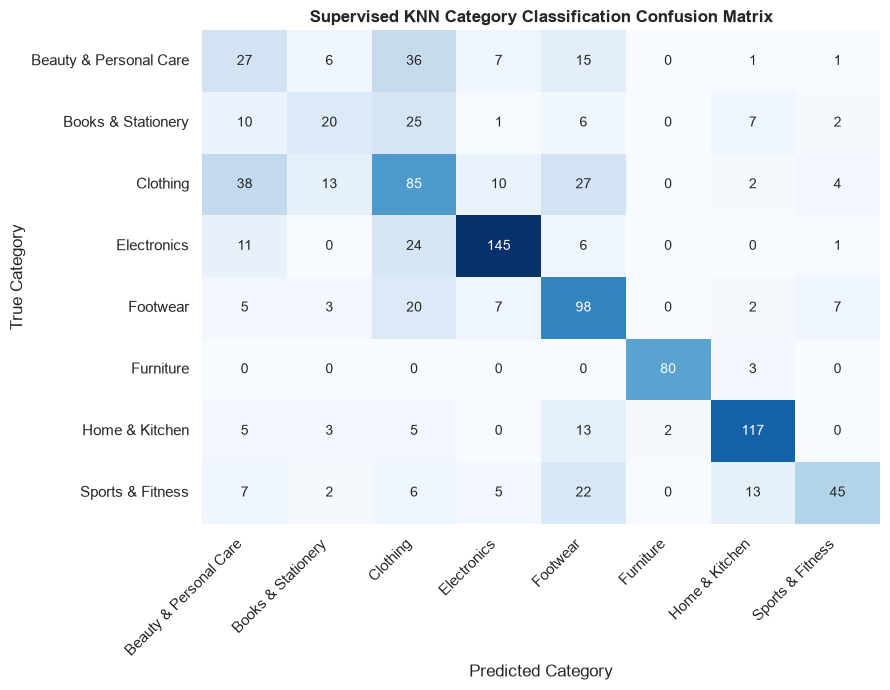

In [7]:
# Train Supervised KNN Classifier
X_sup = X_scaled
y_sup = df["product_category"]

X_train, X_test, y_train, y_test = train_test_split(
    X_sup, y_sup, test_size=0.20, random_state=42, stratify=y_sup
)

knn_classifier = KNeighborsClassifier(n_neighbors=7, weights="distance")
knn_classifier.fit(X_train, y_train)

y_pred = knn_classifier.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Supervised KNN Category Classifier Accuracy: {acc*100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=3))

# Plot Confusion Matrix
plt.figure(figsize=(9, 7))
labels = sorted(y_sup.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False)
plt.title("Supervised KNN Category Classification Confusion Matrix", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Category")
plt.ylabel("True Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Step 7: Module 3: Latency & Scalability Benchmarking
### Comparing Query Latency Across Search Algorithms as Catalog Scales
We evaluate recommendation latency across catalog sizes:
N \in \{1,000,\; 5,000,\; 10,000,\; 25,000,\; 50,000\}

We benchmark three core spatial indexing strategies:
1. **Brute Force (rute)**: Computes exhaustive pairwise distances. Complexity: $\mathcal{O}(N \cdot D)$.
2. **KD-Tree (kd_tree)**: Partitions space along orthogonal feature axes. Query complexity: $\mathcal{O}(D \log N)$.
3. **Ball-Tree (all_tree)**: Partitions space into nested hyperspheres. Ideal for higher-dimensional spaces.

We record the **Median Latency (p50)** and **95th Percentile Tail Latency (p95)** across repeated queries.


In [8]:
from generate_dataset import generate_catalog_dataset

catalog_scales = [1000, 5000, 10000, 25000, 50000]
algorithms = ["brute", "kd_tree", "ball_tree"]
benchmark_data = []

print("Running Latency Benchmark across catalog scales (50 queries each)...")

for size in catalog_scales:
    # Generate scaled catalog slice
    df_slice = generate_catalog_dataset(n_samples=size, random_seed=42)
    X_slice = scaler.fit_transform(df_slice[FEATURE_COLS])
    
    np.random.seed(123)
    sample_idxs = np.random.choice(size, size=min(50, size), replace=False)
    query_vecs = X_slice[sample_idxs]
    
    for algo in algorithms:
        t0 = time.perf_counter()
        model_bench = NearestNeighbors(n_neighbors=10, algorithm=algo, metric="euclidean")
        model_bench.fit(X_slice)
        index_ms = (time.perf_counter() - t0) * 1000.0
        
        times = []
        for qv in query_vecs:
            t_q = time.perf_counter()
            model_bench.kneighbors(qv.reshape(1, -1))
            times.append((time.perf_counter() - t_q) * 1000.0)
            
        times = np.array(times)
        benchmark_data.append({
            "catalog_size": size,
            "algorithm": algo,
            "index_time_ms": round(index_ms, 2),
            "median_latency_ms": round(np.median(times), 4),
            "p95_latency_ms": round(np.percentile(times, 95), 4)
        })

bench_df = pd.DataFrame(benchmark_data)
display(bench_df)


Running Latency Benchmark across catalog scales (50 queries each)...


,catalog_size,algorithm,index_time_ms,median_latency_ms,p95_latency_ms
0,1000,brute,0.22,0.1134,0.2975
1,1000,kd_tree,0.67,0.2232,0.3308
2,1000,ball_tree,0.48,0.2172,0.2524
3,5000,brute,0.26,0.1453,0.1813
4,5000,kd_tree,2.30,0.2262,0.3366
5,5000,ball_tree,1.64,0.2394,0.3584
6,10000,brute,0.27,0.1975,0.3035
7,10000,kd_tree,4.90,0.2215,0.2650
8,10000,ball_tree,3.40,0.2462,0.3258
9,25000,brute,0.44,0.3584,0.5053


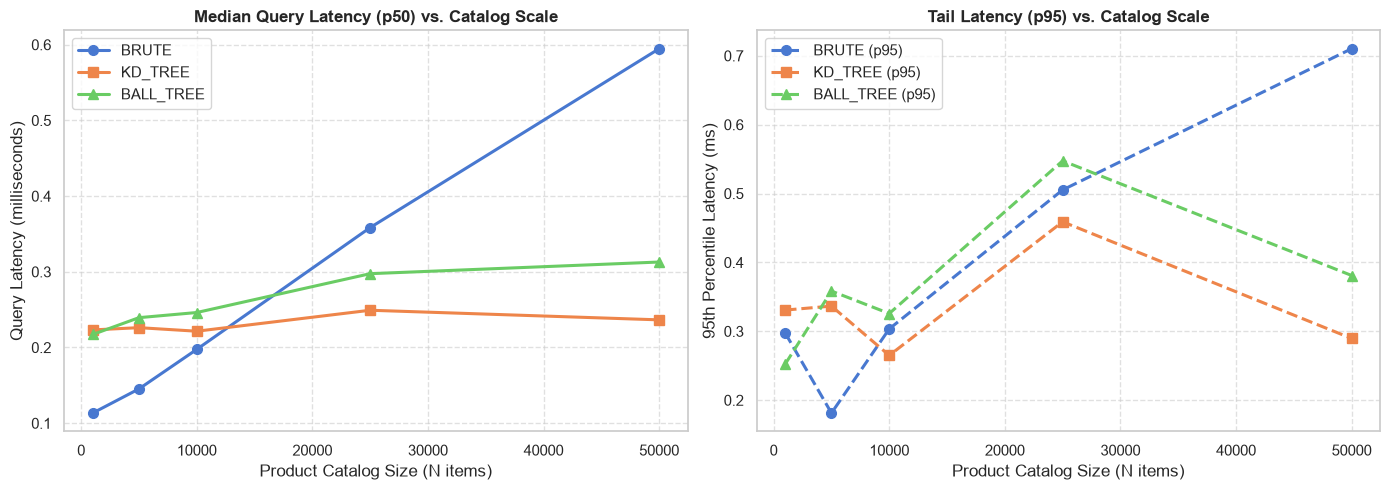

In [9]:
# Plot Benchmark Scaling Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for algo, marker in zip(algorithms, ["o", "s", "^"]):
    sub = bench_df[bench_df["algorithm"] == algo]
    axes[0].plot(
        sub["catalog_size"],
        sub["median_latency_ms"],
        marker=marker,
        linewidth=2.2,
        markersize=7,
        label=f"{algo.upper()}"
    )
axes[0].set_title("Median Query Latency (p50) vs. Catalog Scale", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Product Catalog Size (N items)")
axes[0].set_ylabel("Query Latency (milliseconds)")
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

for algo, marker in zip(algorithms, ["o", "s", "^"]):
    sub = bench_df[bench_df["algorithm"] == algo]
    axes[1].plot(
        sub["catalog_size"],
        sub["p95_latency_ms"],
        marker=marker,
        linewidth=2.2,
        markersize=7,
        linestyle="--",
        label=f"{algo.upper()} (p95)"
    )
axes[1].set_title("Tail Latency (p95) vs. Catalog Scale", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Product Catalog Size (N items)")
axes[1].set_ylabel("95th Percentile Latency (ms)")
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()


## Step 8: Interactive Product Recommendation Demo & Non-Technical View

To make NearestCart user-friendly for non-technical stakeholders (e.g. store managers, shoppers, or evaluators), we provide a clean, minimal recommendation interface that removes technical metric noise (Euclidean distance, raw inverse weights) and displays intuitive commercial attributes:
- **Customer-Facing Match Score (%)**
- **Unit Pricing & 5-Star Ratings**
- **Direct SKU Querying, 'random' sampling, and category browsing**

You can also run this directly in your terminal via `python recommend_and_benchmark.py`.


In [10]:
import random

def display_clean_recommendations(target, rec_df, top_n=5):
    """Displays minimal, customer-friendly recommendations without technical clutter."""
    print("=" * 84)
    print(f"  TARGET PRODUCT: {target['sku_id']} [{target['product_category']}]")
    print(f"  Price: Rs. {target['unit_price']:,.2f}  |  Rating: {target['average_user_rating']:.1f} / 5.0 ({int(target['review_volume']):,} reviews)")
    print("=" * 84)
    
    print(f"\nTOP {min(top_n, len(rec_df))} RECOMMENDED ALTERNATIVES:")
    print("-" * 84)
    print(f"{'#':<3} | {'SKU ID':<10} | {'Category':<16} | {'Price (INR)':<14} | {'Rating':<10} | {'Match':<12}")
    print("-" * 84)
    
    for i, row in rec_df.head(top_n).iterrows():
        rank = row.get('weighted_rank', i + 1)
        sku = row['sku_id']
        cat = row['product_category']
        price_str = f"Rs. {row['unit_price']:,.2f}"
        rating_str = f"{row['average_user_rating']:.1f} / 5.0"
        match_str = f"{row['similarity_score_pct']:.0f}% Match"
        if rank == 1:
            match_str += " (Best)"
        print(f"{rank:<3} | {sku:<10} | {cat:<16} | {price_str:<14} | {rating_str:<10} | {match_str:<12}")
    print("-" * 84)

def interactive_query(sku_query="random", top_n=5):
    """Query any SKU, numeric ID (e.g. 42), 'random', or 'categories'."""
    clean_input = str(sku_query).strip()
    
    if clean_input.lower() == "categories":
        print("\nAvailable Categories & Sample SKUs:")
        for cat, group in df.groupby("product_category"):
            sample_skus = ", ".join(group["sku_id"].head(3).tolist())
            print(f"  * {cat:<24}: e.g. {sample_skus}")
        return
        
    if clean_input.lower() == "random":
        clean_sku = df.iloc[random.randint(0, len(df) - 1)]["sku_id"]
    elif clean_input.isdigit():
        clean_sku = f"SKU_{int(clean_input):05d}"
    else:
        clean_sku = clean_input.upper()
        
    target, recs = retrieve_top_n_recommendations(clean_sku, top_n=top_n)
    weighted = compute_distance_weighted_ranking(recs)
    display_clean_recommendations(target, weighted, top_n=top_n)

# Demo 1: Query specific product (SKU_00004 - Footwear)
interactive_query("SKU_00004", top_n=5)


INTERACTIVE RECOMMENDATION QUERY: SKU_00004
Target SKU:      SKU_00004
Category:        Footwear
Price:           Rs. 1,807.10
Rating:          3.41 / 5.0 (923 reviews)
Physical Dims:   Weight: 758.1g | Volume: 4373.4 cm3
----------------------------------------------------------------------
Top Recommendations (Distance-Weighted Ranking):


,weighted_rank,sku_id,unit_price,average_user_rating,euclidean_distance,similarity_score_pct,weighted_priority_score
0,1,SKU_01540,1430.56,3.45,0.1263,88.78,127.82
1,2,SKU_00969,1597.75,3.48,0.2051,82.98,75.03
2,3,SKU_00358,625.26,3.45,0.3844,72.23,36.13


In [ ]:
# Demo 2: Query a Random Product from the catalog
interactive_query("random", top_n=5)

# Demo 3: Browse Available Categories & Sample SKUs
interactive_query("categories")
